# ForwardGNN on PubMed — Colab runner

Experiments from *Forward Learning of Graph Neural Networks* (Park et al., ICLR 2024), repo `facebookresearch/forwardgnn`.

**Plan**
1. Backprop GCN on PubMed (baseline)
2. Single-Forward GCN on PubMed
3. Single-Forward Top-Down GCN on PubMed (if time allows)

**Why this notebook is structured oddly.** The repo needs `torch==1.13.1` + `torch_geometric==2.2.0`. `src/gnn/message_passing.py` is a vendored copy of PyG 2.2 internals and imports `torch_geometric.nn.conv.utils.inspector` and `torch_scatter.gather_csr`, both removed in PyG 2.3+. Colab's preinstalled stack is far newer, so we build a **separate Python 3.10 virtualenv** and call the training scripts through it. The notebook kernel itself is only a launcher — it never imports torch.

**Run cells 1–7 in order once.** After that, cells 8–11 are the actual experiments and can be re-run freely.

> Set the runtime to a **T4 GPU** (Runtime → Change runtime type). T4 is `sm_75` and is fully covered by the cu117 build. An L4 (`sm_89`) will still work but JIT-compiles kernels on first use.

## 1. Check the runtime

In [1]:
!nvidia-smi || echo "No GPU — this will run on CPU (slower, but PubMed is small enough to be viable)"
import sys; print("Colab kernel Python:", sys.version)

Mon Sep 28 15:57:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             50W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 2. Mount Drive

Colab disconnects. Results, the dataset and the k-fold splits all live on Drive so a disconnect costs you nothing.

The scripts write one JSON per run and **skip runs that already have a result file** (unless `--overwrite-result` is passed). We deliberately do *not* pass that flag below, so re-running a cell after a disconnect resumes where it stopped.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/forwardgnn-experiments'

import os
for sub in ['data', 'datasplits', 'results']:
    os.makedirs(f'{PROJECT_DIR}/{sub}', exist_ok=True)
print("Persistent project dir:", PROJECT_DIR)

Mounted at /content/drive
Persistent project dir: /content/drive/MyDrive/forwardgnn-experiments


## 3. Clone the repo and point its folders at Drive

`src/settings.py` hardcodes `data/`, `datasplits/` and `results/` relative to the repo root, so we symlink those three into Drive rather than patching the code.

In [3]:
import os, shutil, subprocess

REPO = '/content/forwardgnn'
if not os.path.exists(REPO):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/facebookresearch/forwardgnn.git', REPO], check=True)

for sub in ['data', 'datasplits', 'results']:
    p = f'{REPO}/{sub}'
    if os.path.islink(p):
        os.unlink(p)
    elif os.path.isdir(p):
        shutil.rmtree(p)
    os.symlink(f'{PROJECT_DIR}/{sub}', p)

print(subprocess.run(['ls', '-la', REPO], capture_output=True, text=True).stdout)

total 68
drwxr-xr-x 7 root root  4096 Sep 28 15:57 .
drwxr-xr-x 1 root root  4096 Sep 28 15:57 ..
-rw-r--r-- 1 root root  3536 Sep 28 15:57 CODE_OF_CONDUCT.md
-rw-r--r-- 1 root root  1246 Sep 28 15:57 CONTRIBUTING.md
lrwxrwxrwx 1 root root    50 Sep 28 15:57 data -> /content/drive/MyDrive/forwardgnn-experiments/data
lrwxrwxrwx 1 root root    56 Sep 28 15:57 datasplits -> /content/drive/MyDrive/forwardgnn-experiments/datasplits
drwxr-xr-x 4 root root  4096 Sep 28 15:57 exp
drwxr-xr-x 8 root root  4096 Sep 28 15:57 .git
-rw-r--r-- 1 root root    86 Sep 28 15:57 .gitignore
drwxr-xr-x 2 root root  4096 Sep 28 15:57 img
drwxr-xr-x 2 root root  4096 Sep 28 15:57 install
-rw-r--r-- 1 root root 19331 Sep 28 15:57 LICENSE
-rw-r--r-- 1 root root  4230 Sep 28 15:57 README.md
lrwxrwxrwx 1 root root    53 Sep 28 15:57 results -> /content/drive/MyDrive/forwardgnn-experiments/results
drwxr-xr-x 6 root root  4096 Sep 28 15:57 src



In [5]:
import subprocess
r = subprocess.run(
    ['uv', 'pip', 'install', '--python', VENV_PY,
     'torch-scatter', '-f', PYG_WHEELS, '--no-build-isolation'],
    capture_output=True, text=True)
print(r.stdout[-3000:])
print("----- STDERR -----")
print(r.stderr[-3000:])


----- STDERR -----
Using Python 3.10.21 environment at: fgnn-env
error: Failed to build `torch-scatter==2.1.2`
  cause: The build backend returned an error
  cause: Call to `setuptools.build_meta:__legacy__.prepare_metadata_for_build_wheel` failed (exit status: 1)

         [stderr]
         Traceback (most recent call last):
           File "<string>", line 8, in <module>
         ModuleNotFoundError: No module named 'setuptools'

hint: This error likely indicates that `torch-scatter@2.1.2` depends on `setuptools`, but doesn't declare it as a build dependency. If `torch-scatter` is a first-party package, consider adding `setuptools` to its `build-system.requires`. Otherwise, either add it to your `pyproject.toml` under:

[tool.uv.extra-build-dependencies]
torch-scatter = ["setuptools"]

or `uv pip install setuptools` into the environment and re-run with `--no-build-isolation`.



## 4. Build the Python 3.10 environment

`uv` fetches a standalone Python 3.10 (Colab's own Python is too new for torch 1.13.1, which ships wheels only up to cp310).

This cell takes roughly 3–5 minutes. It only needs to run once per session.

In [6]:
import subprocess, shutil, os, re, urllib.request
from urllib.parse import urljoin

VENV    = '/content/fgnn-env'
VENV_PY = f'{VENV}/bin/python'
HAS_GPU = shutil.which('nvidia-smi') is not None and subprocess.run(
    ['nvidia-smi'], capture_output=True).returncode == 0

TORCH_BUILD = 'cu117' if HAS_GPU else 'cpu'
TORCH_INDEX = f'https://download.pytorch.org/whl/{TORCH_BUILD}'
PYG_WHEELS  = f'https://data.pyg.org/whl/torch-1.13.1+{TORCH_BUILD}.html'
print(f"Building for: {TORCH_BUILD}")

def sh(cmd):
    print('$', ' '.join(cmd))
    r = subprocess.run(cmd, text=True, capture_output=True)
    print(r.stdout[-2000:])
    if r.returncode != 0:
        print("----- STDERR -----")
        print(r.stderr[-4000:])
        raise RuntimeError(f'Failed: {" ".join(cmd)}')

# --- venv with pip seeded ---
if not os.path.exists(VENV_PY):
    sh(['uv', 'venv', '--seed', '--python', '3.10', VENV])
sh([VENV_PY, '-m', 'ensurepip', '--upgrade'])
sh([VENV_PY, '-m', 'pip', 'install', '-q', '--upgrade', 'pip', 'setuptools', 'wheel'])

PIP = [VENV_PY, '-m', 'pip', 'install']

# numpy<2 first: torch 1.13 is built against the numpy 1.x ABI
sh(PIP + ['numpy==1.24.4', 'scipy==1.10.1'])
sh(PIP + [f'torch==1.13.1+{TORCH_BUILD}', '--index-url', TORCH_INDEX])

# --- resolve torch_scatter / torch_sparse wheels explicitly ---
ver = subprocess.run(
    [VENV_PY, '-c', 'import sys;print(f"cp{sys.version_info.major}{sys.version_info.minor}")'],
    capture_output=True, text=True).stdout.strip()
print("venv tag:", ver)

html = urllib.request.urlopen(PYG_WHEELS).read().decode()
urls = {}
for pkg in ['torch_scatter', 'torch_sparse']:
    pat = rf'href="([^"]*{pkg}-[^"]*{ver}-{ver}-linux_x86_64\.whl[^"]*)"'
    hits = re.findall(pat, html)
    if not hits:
        raise RuntimeError(
            f"No {pkg} wheel for {ver} at {PYG_WHEELS}. "
            f"Available tags: {sorted(set(re.findall(rf'{pkg}-[^\"]*?-(cp\\d+)-', html)))}")
    urls[pkg] = urljoin(PYG_WHEELS, hits[-1])
    print(f"  {pkg}: {urls[pkg].split('/')[-1][:70]}")

sh(PIP + list(urls.values()))
sh(PIP + ['torch-geometric==2.2.0', 'scikit-learn==1.3.2', 'tqdm'])
print('\nEnvironment built.')

Building for: cu117
$ /content/fgnn-env/bin/python -m ensurepip --upgrade
Looking in links: /tmp/tmpe7znmp0s
Processing /tmp/tmpe7znmp0s/setuptools-79.0.1-py3-none-any.whl
Processing /tmp/tmpe7znmp0s/pip-23.0.1-py3-none-any.whl

$ /content/fgnn-env/bin/python -m pip install -q --upgrade pip setuptools wheel
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 25.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 67.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 8.6 MB/s eta 0:00:00

$ /content/fgnn-env/bin/python -m pip install numpy==1.24.4 scipy==1.10.1

$ /content/fgnn-env/bin/python -m pip install torch==1.13.1+cu117 --index-url https://download.pytorch.org/whl/cu117
Looking in indexes: https://download.pytorch.org/whl/cu117

venv tag: cp310
  torch_scatter: torch_scatter-2.1.1%2Bpt113cu117-cp310-cp310-linux_x86_64.whl
  torch_sparse: torch_sparse-0.6.17%2Bpt113cu117-cp310-cp310-linux_x86_64.whl
$ /content/fgnn-env/bin/

## 5. Verify the environment

This is the checkpoint that catches the PyG-version problem. If `message_passing` imports cleanly, the vendored PyG 2.2 internals resolved correctly.

In [8]:
check = r'''
import torch, torch_geometric, numpy, sys
print("python        :", sys.version.split()[0])
print("torch         :", torch.__version__)
print("torch_geometric:", torch_geometric.__version__)
print("numpy         :", numpy.__version__)
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu           :", torch.cuda.get_device_name(0))

sys.path.insert(0, "/content/forwardgnn/src")
from gnn import GNNConv, CachedGCNConv, CachedSAGEConv   # imports the vendored message_passing
print("repo imports OK -- vendored PyG 2.2 internals resolved")
'''
open('/content/_check.py', 'w').write(check)
!{VENV_PY} /content/_check.py

python        : 3.10.21
torch         : 1.13.1+cu117
torch_geometric: 2.2.0
numpy         : 1.24.4
cuda available: True
gpu           : NVIDIA A100-SXM4-40GB
repo imports OK -- vendored PyG 2.2 internals resolved


## 6. Smoke test — 2 minutes, saves you hours

Tiny runs into a throwaway `--exp-setting`, so nothing pollutes your real results. The first one downloads PubMed (~50 MB) and generates the 5-fold splits into Drive.

If either of these fails, stop and fix it before launching the real jobs.

In [9]:
import subprocess, os

SRC = '/content/forwardgnn/src'
ENV = {**os.environ, 'PYTHONUNBUFFERED': '1'}

def run(script, args, tail=25):
    cmd = [VENV_PY, script] + args
    print('$', ' '.join(cmd), '\n')
    r = subprocess.run(cmd, cwd=SRC, env=ENV, text=True,
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    lines = r.stdout.splitlines()
    print('\n'.join(lines[-tail:]))
    print('\n--- exit code:', r.returncode)
    return r.returncode

# Backprop path
run('train_backprop.py', [
    '--exp-setting', 'smoke-test', '--dataset', 'CitationFull-PubMed', '--task', 'node-class',
    '--model', 'GNN-GCN', '--num-layers', '2', '--num-runs', '1', '--seed', '100',
    '--epochs', '5', '--val-every', '2', '--lr', '0.001', '--patience', '5',
    '--num-hidden', '128', '--overwrite-result',
])

$ /content/fgnn-env/bin/python train_backprop.py --exp-setting smoke-test --dataset CitationFull-PubMed --task node-class --model GNN-GCN --num-layers 2 --num-runs 1 --seed 100 --epochs 5 --val-every 2 --lr 0.001 --patience 5 --num-hidden 128 --overwrite-result 

Processing...
Done!
2026-09-28 16:05:27,005 [INFO] [datasplit.generate_node_splits] node splits generated for CitationFull-PubMed
2026-09-28 16:05:27,010 [INFO] [dataloader.load_node_classification_data] loaded node split from /content/drive/MyDrive/forwardgnn-experiments/datasplits/CitationFull-PubMed/node-5splits

Dataset (CitationFull-PubMed):
Data(x=[19717, 500], edge_index=[2, 88648], y=[19717], train_mask=[19717], val_mask=[19717], test_mask=[19717], num_classes=3)
- Number of classes: 3
- Number of training nodes: 12618
- Number of validation nodes: 3155
- Number of testing nodes: 3944
GCN(500, 3, num_layers=2)

Epoch: 003, Train Loss=1.0925, Val Acc=0.5502: 100%|##########| 5/5 [00:01<00:00,  4.27it/s]
2026-09-28 16:05

0

In [10]:
# Forward-learning path (the one that breaks on a wrong PyG version)
run('train_forward.py', [
    '--exp-setting', 'smoke-test', '--dataset', 'CitationFull-PubMed', '--task', 'node-class',
    '--model', 'GNN_SingleForward-GCN', '--num-layers', '4', '--num-runs', '1', '--seed', '100',
    '--epochs', '5', '--val-every', '2', '--lr', '0.001', '--patience', '5',
    '--num-hidden', '128', '--append-label', 'none',
    '--aug-edge-direction', 'bidirection', '--overwrite-result',
])

$ /content/fgnn-env/bin/python train_forward.py --exp-setting smoke-test --dataset CitationFull-PubMed --task node-class --model GNN_SingleForward-GCN --num-layers 2 --num-runs 1 --seed 100 --epochs 5 --val-every 2 --lr 0.001 --patience 5 --num-hidden 128 --append-label none --aug-edge-direction bidirection --overwrite-result 

[Layer 0: Epoch-4] Loss=0.9020 | Val: Acc=56.51 (BestAcc=56.5135@Epoch-3) | Test: Acc=56.11 (BestAcc=56.1105@Epoch-3): 100%|##########| 5/5 [00:01<00:00,  5.51it/s]
[Layer 0: Epoch-4] Loss=0.9020 | Val: Acc=56.51 (BestAcc=56.5135@Epoch-3) | Test: Acc=56.11 (BestAcc=56.1105@Epoch-3): 100%|##########| 5/5 [00:01<00:00,  3.89it/s]
2026-09-28 16:05:57,595 [INFO] [gnn_sf.forward_train] Finished training layer 1 / 2.

[Layer-0] Test Accuracy : 56.11%


  0%|          | 0/5 [00:00<?, ?it/s]
[Layer 1: Epoch-0] Loss=0.9089 |  | :   0%|          | 0/5 [00:00<?, ?it/s]
[Layer 1: Epoch-1] Loss=0.8700 | Val: Acc=64.91 (BestAcc=64.9128@Epoch-1) | Test: Acc=64.48 (BestAcc=64.4

0

## 7. Job runner

Streams output live so Colab doesn't treat the session as idle, and writes a full log per job to Drive.

Every job below mirrors `exp/nodeclass/*.sh` exactly, except that `--overwrite-result` is omitted so interrupted sweeps resume.

In [11]:
import subprocess, os, time, datetime, json, pathlib

SRC     = '/content/forwardgnn/src'
LOG_DIR = pathlib.Path(PROJECT_DIR) / 'logs'
LOG_DIR.mkdir(exist_ok=True)

COMMON = ['--exp-setting', 'perf-results', '--dataset', 'CitationFull-PubMed',
          '--task', 'node-class', '--num-runs', '5', '--seed', '100',
          '--epochs', '1000', '--val-every', '2', '--lr', '0.001',
          '--patience', '100', '--num-hidden', '128']

FORWARD_EXTRA = ['--append-label', 'none', '--aug-edge-direction', 'bidirection']

def run_job(script, model, num_layers, extra=()):
    args = COMMON + ['--model', model, '--num-layers', str(num_layers)] + list(extra)
    tag  = f"{model}-L{num_layers}"
    log  = LOG_DIR / f"{tag}-{datetime.datetime.now():%Y%m%d_%H%M%S}.log"
    print(f"\n{'='*72}\n  {tag}\n  log: {log}\n{'='*72}")
    t0 = time.time()
    with open(log, 'w') as f:
        p = subprocess.Popen([VENV_PY, script] + args, cwd=SRC,
                             env={**os.environ, 'PYTHONUNBUFFERED': '1'},
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in p.stdout:
            f.write(line)
            if any(k in line for k in ('Test Performance', 'Error', 'Traceback',
                                       'Starting run', 'Skipping run')):
                print(line.rstrip())
        p.wait()
    print(f"  -> exit {p.returncode} in {time.time()-t0:.0f}s")
    return p.returncode

print("Runner ready.")

Runner ready.


## 8. Experiment 1 — Backprop GCN baseline

Matches `exp/nodeclass/nodeclass-bp.sh`: depths 1–4, 5 runs each.

Expected wall time on a T4: roughly 10–25 minutes total. PubMed is 19,717 nodes with 500 features, trained full-batch, so each epoch is milliseconds; early stopping (patience 100) usually fires well before 1000 epochs.

In [14]:
for L in [1, 2, 3, 4]:
    run_job('train_backprop.py', 'GNN-GCN', L)


  GNN-GCN-L1
  log: /content/drive/MyDrive/forwardgnn-experiments/logs/GNN-GCN-L1-20260928_162137.log
Starting run-0 of GNN-GCN on CitationFull-PubMed (seed=10100)
Starting run-1 of GNN-GCN on CitationFull-PubMed (seed=10103)
Starting run-2 of GNN-GCN on CitationFull-PubMed (seed=10106)
Starting run-3 of GNN-GCN on CitationFull-PubMed (seed=10109)
Starting run-4 of GNN-GCN on CitationFull-PubMed (seed=10112)
Test Performance (5 runs): 0.638231%±0.0103
  -> exit 0 in 19s

  GNN-GCN-L2
  log: /content/drive/MyDrive/forwardgnn-experiments/logs/GNN-GCN-L2-20260928_162156.log
2026-09-28 16:21:58,362 [INFO] [train_backprop.main] Skipping run-0: already evaluated.
2026-09-28 16:21:58,363 [INFO] [train_backprop.main] Skipping run-1: already evaluated.
2026-09-28 16:21:58,364 [INFO] [train_backprop.main] Skipping run-2: already evaluated.
2026-09-28 16:21:58,365 [INFO] [train_backprop.main] Skipping run-3: already evaluated.
2026-09-28 16:21:58,366 [INFO] [train_backprop.main] Skipping run-4: 

## 9. Experiment 2 — Single-Forward GCN

Matches `exp/nodeclass/nodeclass-sf.sh`. Note the shipped script only runs **`num_layers=4`** for SF, while the BP script sweeps 1–4. Depths 1–3 are included below so your baseline comparison is like-for-like — drop them if you're short on time, but say so in your write-up.

Slower than backprop here: each layer is trained greedily for up to 1000 epochs, so a 4-layer model is ~4 sequential training runs. Budget 45–90 minutes for the full set.

The paper's reported SF speed-up comes from caching the aggregation, which is **opt-in via the model string** (`GNN_SingleForward-CachedGCN`). The shipped scripts don't use it, so don't expect the speed-up from this cell.

In [15]:
for L in [1, 2, 3, 4]:
    run_job('train_forward.py', 'GNN_SingleForward-GCN', L, FORWARD_EXTRA)


  GNN_SingleForward-GCN-L1
  log: /content/drive/MyDrive/forwardgnn-experiments/logs/GNN_SingleForward-GCN-L1-20260928_162737.log
2026-09-28 16:27:40,071 [INFO] [train_forward.main] Skipping run-0: already evaluated.
2026-09-28 16:27:40,072 [INFO] [train_forward.main] Skipping run-1: already evaluated.
2026-09-28 16:27:40,073 [INFO] [train_forward.main] Skipping run-2: already evaluated.
2026-09-28 16:27:40,074 [INFO] [train_forward.main] Skipping run-3: already evaluated.
2026-09-28 16:27:40,075 [INFO] [train_forward.main] Skipping run-4: already evaluated.
Test Performance (5 runs): 87.021346%±0.2188
  -> exit 0 in 2s

  GNN_SingleForward-GCN-L2
  log: /content/drive/MyDrive/forwardgnn-experiments/logs/GNN_SingleForward-GCN-L2-20260928_162740.log
2026-09-28 16:27:42,497 [INFO] [train_forward.main] Skipping run-0: already evaluated.
2026-09-28 16:27:42,498 [INFO] [train_forward.main] Skipping run-1: already evaluated.
2026-09-28 16:27:42,499 [INFO] [train_forward.main] Skipping run-2

## 10. Experiment 3 — Single-Forward Top-Down GCN

The repo has **two** top-down variants. The paper's "SF-TopDown" is `Top2Input` (top-down signal fed back into the next round's input). `Top2Loss` feeds it into the loss instead and is the variant that degrades at depth.

Both add `--alternating-update`. Run `Top2Input` first — that's the one your notes refer to.

In [16]:
for L in [1, 2, 3, 4]:
    run_job('train_forward.py', 'GNN_Top2Input_SingleForward-GCN', L,
            FORWARD_EXTRA + ['--alternating-update'])


  GNN_Top2Input_SingleForward-GCN-L1
  log: /content/drive/MyDrive/forwardgnn-experiments/logs/GNN_Top2Input_SingleForward-GCN-L1-20260928_162857.log
Starting run-0 of GNN_Top2Input_SingleForward-GCN on CitationFull-PubMed (seed=10100)
Starting run-1 of GNN_Top2Input_SingleForward-GCN on CitationFull-PubMed (seed=10103)
Starting run-2 of GNN_Top2Input_SingleForward-GCN on CitationFull-PubMed (seed=10106)
Starting run-3 of GNN_Top2Input_SingleForward-GCN on CitationFull-PubMed (seed=10109)
Starting run-4 of GNN_Top2Input_SingleForward-GCN on CitationFull-PubMed (seed=10112)
Test Performance (5 runs): 77.907438%±0.9277
  -> exit 0 in 159s

  GNN_Top2Input_SingleForward-GCN-L2
  log: /content/drive/MyDrive/forwardgnn-experiments/logs/GNN_Top2Input_SingleForward-GCN-L2-20260928_163135.log
Starting run-0 of GNN_Top2Input_SingleForward-GCN on CitationFull-PubMed (seed=10100)
Starting run-1 of GNN_Top2Input_SingleForward-GCN on CitationFull-PubMed (seed=10103)
Starting run-2 of GNN_Top2Input

In [17]:
for L in [1, 2, 3, 4]:
    run_job('train_forward.py', 'GNN_Top2Loss_SingleForward-GCN', L,
           FORWARD_EXTRA + ['--alternating-update'])


  GNN_Top2Loss_SingleForward-GCN-L1
  log: /content/drive/MyDrive/forwardgnn-experiments/logs/GNN_Top2Loss_SingleForward-GCN-L1-20260928_165658.log
Starting run-0 of GNN_Top2Loss_SingleForward-GCN on CitationFull-PubMed (seed=10100)
Starting run-1 of GNN_Top2Loss_SingleForward-GCN on CitationFull-PubMed (seed=10103)
Starting run-2 of GNN_Top2Loss_SingleForward-GCN on CitationFull-PubMed (seed=10106)
Starting run-3 of GNN_Top2Loss_SingleForward-GCN on CitationFull-PubMed (seed=10109)
Starting run-4 of GNN_Top2Loss_SingleForward-GCN on CitationFull-PubMed (seed=10112)
Test Performance (5 runs): 86.869190%±0.5042
  -> exit 0 in 137s

  GNN_Top2Loss_SingleForward-GCN-L2
  log: /content/drive/MyDrive/forwardgnn-experiments/logs/GNN_Top2Loss_SingleForward-GCN-L2-20260928_165915.log
Starting run-0 of GNN_Top2Loss_SingleForward-GCN on CitationFull-PubMed (seed=10100)
Starting run-1 of GNN_Top2Loss_SingleForward-GCN on CitationFull-PubMed (seed=10103)
Starting run-2 of GNN_Top2Loss_SingleForwa

## 11. Collect results

Reads every per-run JSON and aggregates to mean ± std over the 5 splits — the number that goes in your table.

                  label  num_layers  mean  std  n  paper  delta   time
          Backprop (BP)           1 63.82 1.16  5    NaN    NaN   3.11
          Backprop (BP)           2 86.75 0.34  5    NaN    NaN  23.12
          Backprop (BP)           3 87.00 0.76  5    NaN    NaN  32.38
          Backprop (BP)           4 85.98 0.58  5    NaN    NaN  30.68
SF Top-Down (Top2Input)           1 77.91 1.04  5    NaN    NaN  30.63
SF Top-Down (Top2Input)           2 83.36 0.74  5    NaN    NaN  62.79
SF Top-Down (Top2Input)           3 84.01 0.74  5    NaN    NaN  94.86
SF Top-Down (Top2Input)           4 84.41 0.64  5    NaN    NaN 133.91
 SF Top-Down (Top2Loss)           1 86.87 0.56  5    NaN    NaN  26.57
 SF Top-Down (Top2Loss)           2 86.51 0.31  5    NaN    NaN  44.18
 SF Top-Down (Top2Loss)           3 86.11 0.62  5    NaN    NaN  80.07
 SF Top-Down (Top2Loss)           4 85.82 0.87  5    NaN    NaN  95.32
    Single Forward (SF)           1 87.02 0.24  5    NaN    NaN  15.03
    Si

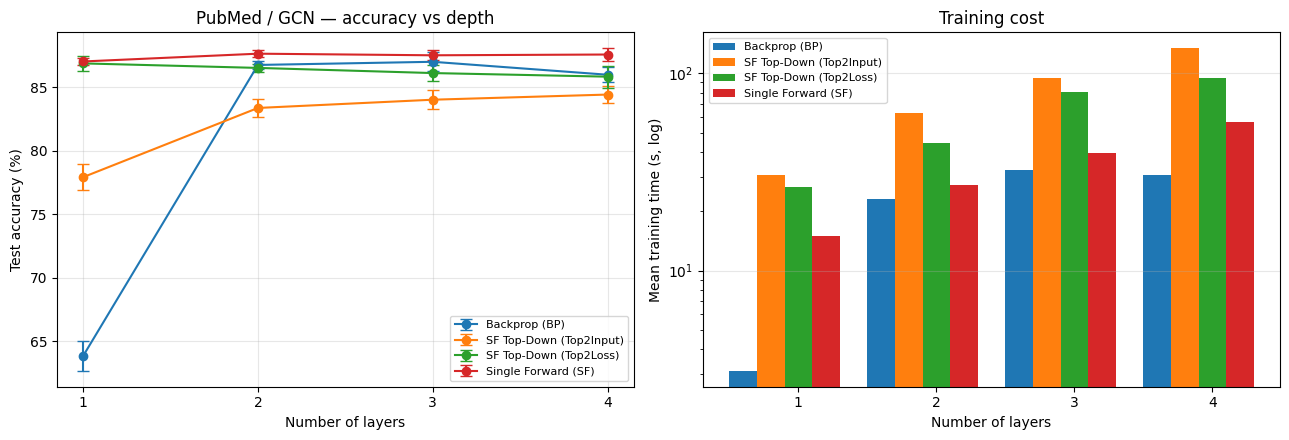

In [18]:
import json, glob, pandas as pd, numpy as np
import matplotlib.pyplot as plt

LABELS = {
    'GNN-GCN':                          'Backprop (BP)',
    'GNN_SingleForward-GCN':            'Single Forward (SF)',
    'GNN_Top2Input_SingleForward-GCN':  'SF Top-Down (Top2Input)',
    'GNN_Top2Loss_SingleForward-GCN':   'SF Top-Down (Top2Loss)',
}

# Fill in from the paper's PubMed/GCN appendix table: (model_key, num_layers) -> accuracy %
PAPER = {
    # ('GNN-GCN', 4): 00.00,
    # ('GNN_SingleForward-GCN', 4): 00.00,
}

rows = []
for f in glob.glob(f'{PROJECT_DIR}/results/perf-results/CitationFull-PubMed/node-class/*.json'):
    d = json.load(open(f))
    perf = d['perf']
    # BP writes a fraction (eval_utils), forward writes a percent (gnn_sf.py). Normalise.
    if d['model'].startswith('GNN-'):
        perf *= 100
    rows.append({'model': d['model'], 'label': LABELS.get(d['model'], d['model']),
                 'num_layers': d['num_layers'], 'run': d['run_i'],
                 'perf': perf, 'train_time': d.get('train_time')})

df = pd.DataFrame(rows)
assert not df.empty, 'No results found.'
assert df['perf'].between(0, 100).all(), 'Scale check failed — inspect raw perf values.'

agg = (df.groupby(['model', 'label', 'num_layers'])
         .agg(mean=('perf', 'mean'), std=('perf', 'std'),
              time=('train_time', 'mean'), n=('run', 'count'))
         .reset_index().sort_values(['label', 'num_layers']))

agg['paper'] = [PAPER.get((m, l), np.nan) for m, l in zip(agg['model'], agg['num_layers'])]
agg['delta'] = agg['mean'] - agg['paper']
print(agg[['label', 'num_layers', 'mean', 'std', 'n', 'paper', 'delta', 'time']]
      .to_string(index=False, float_format=lambda v: f'{v:.2f}'))
agg.to_csv(f'{PROJECT_DIR}/summary.csv', index=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for lbl, g in agg.groupby('label'):
    g = g.sort_values('num_layers')
    ax1.errorbar(g['num_layers'], g['mean'], yerr=g['std'],
                 marker='o', capsize=4, label=lbl)
    if g['paper'].notna().any():
        ax1.plot(g['num_layers'], g['paper'], linestyle='--', marker='x',
                 alpha=0.5, color=ax1.lines[-1].get_color())
ax1.set_xlabel('Number of layers'); ax1.set_ylabel('Test accuracy (%)')
ax1.set_xticks([1, 2, 3, 4]); ax1.set_title('PubMed / GCN — accuracy vs depth')
ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

width, labels = 0.8 / max(agg['label'].nunique(), 1), sorted(agg['label'].unique())
for i, lbl in enumerate(labels):
    g = agg[agg['label'] == lbl].sort_values('num_layers')
    ax2.bar(g['num_layers'] + i * width - 0.4, g['time'], width, label=lbl)
ax2.set_yscale('log'); ax2.set_xlabel('Number of layers')
ax2.set_ylabel('Mean training time (s, log)')
ax2.set_xticks([1, 2, 3, 4]); ax2.set_title('Training cost')
ax2.legend(fontsize=8); ax2.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/results_pubmed_gcn.png', dpi=150)
plt.show()

## Troubleshooting

**`ModuleNotFoundError: torch_geometric.nn.conv.utils.inspector`** — PyG 2.3+ got installed. Delete `/content/fgnn-env` and re-run cell 4.

**`numpy.dtype size changed` / ABI warnings** — numpy 2.x leaked in. Re-run cell 4; the `numpy==1.24.4` pin must come first.

**`torch-sparse` tries to compile from source** — the `-f https://data.pyg.org/whl/...` index didn't match. Confirm the torch build string printed in cell 4 matches the wheel URL.

**Session disconnects mid-sweep** — re-run cells 2–5, then the experiment cell. Completed runs are skipped automatically because `--overwrite-result` is omitted.

**CUDA OOM** — unlikely on PubMed, but if it happens the forward variants hold per-layer optimiser state; lower `--num-hidden` to 64 and note the deviation.

## Things worth recording as you go

- Wall-clock per method. The paper's timing claims are a headline result, and your numbers won't match theirs unless you also run the `Cached` variants.
- Which depths you actually completed for each method.
- Whether your BP baseline numbers land near the paper's PubMed table. If they don't, the split generation (`KFold`, `random_state=101`) is the first thing to check.

***Next Step: GCN, SAGE, GAT - BP, SF, SF-Top2Down, SF-Top2Input (PubMed, Amazon, GitHub, CiteSeer) 1 to 4 Layers
GPU Memory Usage (optional for now, needed later)***